# 04. The Pass-Through Curve: how much delay does extra ground time absorb?

**Project:** Buffer Delay Allocation Engine (Analytics Capstone Project, Team T19)
**Team:** Vaibhav Maheshwari (BA05057), Prashansa Naomi Konduru (BA05042), Anil Kumar (BA05008)
**Faculty:** Mr. Nikhil D Jonathan
**Data:** `aa_clean_v1.0.parquet` (tag `data-v1.0`): 1,641,071 American Airlines mainline flights, 1 Jan 2025 to 31 Aug 2026

**What this notebook does.** The whole project rests on one question: *if an aircraft arrives late, how much of that delay is still there when it leaves again,
and how does the planned ground time change that?* This notebook measures that, turns it into a smooth curve, tests the curve on later data it has never seen,
and checks whether it holds for different airports, times of day and disruption days. The simulator in notebook 06 uses this curve.

## How to run this notebook

You need one data file, **`aa_clean_v1.0.parquet`** (68 MB, the cleaned flight data from D2), and these Python packages: pandas, numpy, matplotlib, pyarrow, scikit-learn.
It takes about 1 to 2 minutes and needs about 4 GB of free memory (a normal laptop or free Google Colab is enough). Then choose *Restart and Run All*.

| Where you run it | What to do |
|---|---|
| **Your laptop** (Jupyter, VS Code, Anaconda) | Put `aa_clean_v1.0.parquet` in the same folder as this notebook (or in a folder called `data`). If a package is missing, run `pip install pandas numpy matplotlib pyarrow scikit-learn` once. |
| **Google Colab** | Upload this notebook (File, then Upload notebook). Run the first code cell. When it asks, click *Choose files* and select `aa_clean_v1.0.parquet` (or upload the file to the Colab file panel first). Nothing needs to be installed. |

The notebook checks the data file against its published checksum, so you know it is the exact dataset from D2. Charts and tables are saved in a
folder called `modelling_outputs` next to the notebook (or `docs/modelling` if it is run inside the project repository).

## Words used in this notebook

| Word | Meaning |
|---|---|
| **Turnaround** | The stop between two flights of the same aircraft. |
| **Inbound delay (A)** | How late the first flight arrived, in minutes. |
| **Outbound delay (D)** | How late the next flight left, in minutes. |
| **Scheduled ground time** | The planned gap between landing and the next departure, in minutes. |
| **Pass-through** | Minutes of outbound delay for each minute of inbound delay. 1.0 means all the delay is passed on. 0 means all of it is absorbed. |
| **95% range** | A range that would contain the true value in 95 of 100 repeats. We build it by re-drawing whole *days* at random. |
| **Training / validation / test** | Jan to Sep 2025, Oct to Dec 2025, Jan to Aug 2026. We fit on training, check on validation, and report on test. |

## 1. Setup and data check

In [1]:
import sys, hashlib, json, warnings
from pathlib import Path

# 1. Check that the packages we need are installed (on Google Colab they already are).
PKGS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "pyarrow": "pyarrow", "sklearn": "scikit-learn"}          # import name -> pip name
missing = []
for module, pip_name in PKGS.items():
    try:
        __import__(module)
    except ImportError:
        missing.append(pip_name)
if missing:
    raise ImportError("Please install the missing packages, then run this cell again:\n    pip install " + " ".join(missing))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10,
                     "legend.frameon": False, "figure.autolayout": True})
BLUE, ORANGE, RED, GREEN, GREY, LIGHT = "#1F3A5F", "#E08A1E", "#C0392B", "#2E8B57", "#8A94A6", "#C9D3E3"
SPLITS = ["train", "validate", "test"]
SEED = 42
RESULTS = {}          # every number we quote is stored here and saved to a .json file at the end
thousands = FuncFormatter(lambda v, pos: f"{v:,.0f}")

# 2. Find the data file: next to the notebook, in 'data' folders, in the Colab file area, or in Downloads.
FILENAME = "aa_clean_v1.0.parquet"
EXPECTED_SHA256 = "3a18a9eafffa77ae74db70579be84255f8b04978efdcdb84524bd2900297f14a"   # published in data/CHECKSUMS.sha256
IN_COLAB = "google.colab" in sys.modules

def locate():
    here = Path.cwd().resolve()
    places = []
    for folder in [here, *here.parents]:
        places += [folder, folder / "data", folder / "data" / "processed"]
    places += [Path("/content"), Path("/content/data"), Path("/content/drive/MyDrive"),
               Path.home() / "Downloads", Path.home() / "Desktop",
               Path("/Volumes/workspace/default/bufferengine/processed")]          # Databricks Volume used by this project
    places += sorted(Path("/Volumes").glob("*/*/*/processed")) if Path("/Volumes").exists() else []   # any other Databricks Volume
    for folder in places:
        if (folder / FILENAME).exists():
            return folder / FILENAME
    return None

PARQUET = locate()
if PARQUET is None and IN_COLAB:
    from google.colab import files
    print(f"Please choose the file {FILENAME} from your computer (68 MB). The upload takes about a minute.")
    files.upload()
    PARQUET = locate()
if PARQUET is None:
    raise FileNotFoundError(f"Could not find {FILENAME}. Put it in the same folder as this notebook (or in a folder called 'data'), "
                            "then run again. On Google Colab, run this cell again and choose the file when asked.")

# 3. Where to save charts and tables.
in_repo = PARQUET.parent.name == "processed" and PARQUET.parent.parent.name == "data" and (PARQUET.parent.parent.parent / "docs").exists()
OUT = (PARQUET.parent.parent.parent / "docs" / "modelling") if in_repo else Path.cwd() / "modelling_outputs"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

def say(text):
    display(Markdown(text))

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o

def write_results(filename):
    (OUT / filename).write_text(json.dumps(_clean(RESULTS), indent=1))
    print(f"Saved {filename} and {len(list(FIG.glob('*.png')))} chart files in the folder '{OUT.name}'.")

# 4. Make sure this is exactly the published dataset.
actual = hashlib.sha256(PARQUET.read_bytes()).hexdigest()
print("Data file          :", PARQUET.name)
print("Python / pandas    :", sys.version.split()[0], "/", pd.__version__)
print("Checksum matches D2:", actual == EXPECTED_SHA256)
assert actual == EXPECTED_SHA256, "This file is not the published aa_clean_v1.0.parquet (tag data-v1.0). Please download it again."

Data file          : aa_clean_v1.0.parquet
Python / pandas    : 3.13.16 / 3.1.0
Checksum matches D2: True


## Building the turnaround table

A **turnaround** is the stop on the ground between two flights of the same aircraft. The buffer question lives here, so every model in this
project works on one row per turnaround. We rebuild the table directly from `aa_clean_v1.0`, so nothing else is needed.

**In plain words, the code below does five things:**
1. Puts each aircraft's flights in time order.
2. Looks at the aircraft's previous flight for every flight.
3. Keeps the pair only if both flights flew, the first landed where the second takes off, they are on the same day, and the planned gap is above zero.
4. Records the **scheduled ground time** (planned gap in minutes), the **inbound delay** `A` (arrival delay of the first flight) and the **outbound delay** `D` (departure delay of the second flight).
5. Adds facts that are known from the timetable alone (hour, airport, distance, how many flights the aircraft has already flown that day). These are the only things the prediction models are allowed to use.

`A` and `D` are limited to the 0.5% and 99.5% levels of the *training* period, so a few extreme flights cannot dominate the averages.

In [2]:
COLS = ["FlightDate", "Month", "DayOfWeek", "Tail_Number", "Origin", "Dest", "Distance", "crs_dep_min", "crs_arr_min",
        "DepDelay", "ArrDelay", "Cancelled", "Diverted", "is_operated", "crs_dep_utc", "crs_arr_utc", "split"]
df = pd.read_parquet(PARQUET, columns=COLS)
df["FlightDate"] = pd.to_datetime(df["FlightDate"])
print(f"{len(df):,} flights loaded, {df.FlightDate.min().date()} to {df.FlightDate.max().date()}")

# limits for extreme delays, learned on the training period only
cap_lo, cap_hi = df.loc[(df.split == "train") & df.ArrDelay.notna(), "ArrDelay"].quantile([0.005, 0.995]).values
dcap_lo, dcap_hi = df.loc[(df.split == "train") & df.DepDelay.notna(), "DepDelay"].quantile([0.005, 0.995]).values
TOP10 = df.Origin.value_counts().head(10).index.tolist()                     # ten busiest departure airports
daily_cancel = df.groupby("FlightDate").Cancelled.mean()
STORM = set(daily_cancel[daily_cancel > 0.10].index)                          # disruption days: more than 10% of flights cancelled
AIRPORTS = sorted(set(df.Origin) | set(df.Dest))

d = df.loc[df.Tail_Number.notna()].sort_values(["Tail_Number", "crs_dep_utc"]).copy()
day = d.groupby(["Tail_Number", "FlightDate"])
d["legno"] = day.cumcount() + 1                                               # which flight of the aircraft's day this is (timetable fact)
d["mins_since_first"] = d.crs_dep_min - day.crs_dep_min.transform("min")      # minutes since the aircraft's first planned departure of the day
g = d.groupby("Tail_Number", sort=False)
d["prev_dest"] = g["Dest"].shift(); d["prev_origin"] = g["Origin"].shift(); d["prev_dist"] = g["Distance"].shift()
d["prev_arr_utc"] = g["crs_arr_utc"].shift(); d["prev_date"] = g["FlightDate"].shift()
d["prev_dep_hr"] = g["crs_dep_min"].shift() // 60; d["prev_arr_hr"] = g["crs_arr_min"].shift() // 60
d["A_raw"] = g["ArrDelay"].shift()
d["prev_operated"] = g["is_operated"].shift().eq(True); d["prev_notdiv"] = g["Diverted"].shift().eq(0)
d["sg"] = (d.crs_dep_utc - d.prev_arr_utc).dt.total_seconds() / 60            # scheduled ground time in minutes

link = (d.is_operated & (d.Diverted == 0) & d.prev_operated & d.prev_notdiv & (d.prev_dest == d.Origin)
        & (d.sg > 0) & (d.FlightDate == d.prev_date))
T = d.loc[link, ["Tail_Number", "Origin", "prev_origin", "FlightDate", "split", "Month", "DayOfWeek", "crs_dep_min", "sg", "Distance",
                 "prev_dist", "legno", "mins_since_first", "prev_dep_hr", "prev_arr_hr", "A_raw", "DepDelay"]].rename(
    columns={"Origin": "station", "DepDelay": "D_raw"}).dropna(subset=["A_raw", "D_raw"]).copy()
T["A"] = T.A_raw.clip(cap_lo, cap_hi); T["D"] = T.D_raw.clip(dcap_lo, dcap_hi)
T["hr"] = (T.crs_dep_min // 60).clip(0, 23)
T["hub"] = T.station.isin(TOP10).astype(int)
T["storm"] = T.FlightDate.isin(STORM)
for c in ["station", "prev_origin"]:
    T[c] = pd.Categorical(T[c], categories=AIRPORTS)
T = T.reset_index(drop=True)
del d, g, day, link, df                                                       # free memory

print(f"Turnarounds built: {len(T):,}   (disruption days: {len(STORM)}; ten busiest airports: {', '.join(TOP10)})")
display(T.groupby("split").agg(turnarounds=("sg", "size"), first_day=("FlightDate", "min"), last_day=("FlightDate", "max"),
                               median_ground_min=("sg", "median"), mean_inbound_delay=("A", "mean"), mean_outbound_delay=("D", "mean")).loc[SPLITS].round(1))
RESULTS["n_turnarounds"] = int(len(T)); RESULTS["n_storm_days"] = len(STORM); RESULTS["top10"] = TOP10

1,641,071 flights loaded, 2025-01-01 to 2026-08-31


Turnarounds built: 1,060,740   (disruption days: 27; ten busiest airports: DFW, CLT, MIA, ORD, PHX, PHL, LAX, DCA, MCO, LGA)


,turnarounds,first_day,last_day,median_ground_min,mean_inbound_delay,mean_outbound_delay
split,,,,,,
train,474633,2025-01-01,2025-09-30,61.0,5.9,15.9
validate,160835,2025-10-01,2025-12-31,61.0,4.0,13.6
test,425272,2026-01-01,2026-08-31,60.0,4.8,17.0


In [3]:
def _boot(S, B, seed):
    """Re-draw whole days at random, B times, and add up the stored sums (groups x days x stats)."""
    rng = np.random.default_rng(seed)
    nd = S.shape[1]
    idx = rng.integers(0, nd, size=(B, nd))
    return S[:, idx, :].sum(axis=2)

def slope_table(frame, group, labels, B=200, seed=SEED, min_n=300):
    """Pass-through (slope of outbound delay D on inbound delay A) for each group, with a 95% day-block bootstrap range."""
    f = frame[[group, "FlightDate", "A", "D"]].copy()
    f["AA"] = f.A * f.A; f["AD"] = f.A * f.D; f["n"] = 1.0
    days = np.sort(f.FlightDate.unique()); di = pd.Index(days)
    agg = f.groupby([group, "FlightDate"]).agg(n=("n", "sum"), sA=("A", "sum"), sD=("D", "sum"), sAA=("AA", "sum"), sAD=("AD", "sum")).reset_index()
    S = np.zeros((len(labels), len(days), 5))
    S[agg[group].values.astype(int), di.get_indexer(agg.FlightDate), :] = agg[["n", "sA", "sD", "sAA", "sAD"]].values
    def slope(M):
        n, sA, sD, sAA, sAD = [M[..., k] for k in range(5)]
        with np.errstate(divide="ignore", invalid="ignore"):
            return (n * sAD - sA * sD) / (n * sAA - sA ** 2)
    pt = slope(S.sum(axis=1)); bs = slope(_boot(S, B, seed)) if B > 1 else np.full((len(labels), 2), np.nan)
    out = pd.DataFrame({"group": labels, "n": S[..., 0].sum(axis=1).astype(int), "slope": pt,
                        "lo": np.nanpercentile(bs, 2.5, axis=1) if B > 1 else np.nan,
                        "hi": np.nanpercentile(bs, 97.5, axis=1) if B > 1 else np.nan})
    out.loc[out.n < min_n, ["slope", "lo", "hi"]] = np.nan
    return out

## 2. Measuring pass-through for every ground-time group

We look only at turnarounds where the inbound flight was late (A > 0), because those are the ones where there is a delay to absorb.
For each group of scheduled ground times we ask: **for every extra minute of inbound delay, how many extra minutes of outbound delay do we see?**
(This is the slope of a straight line through the points.) We fit on the training period only.

**What to look for.** Is the curve flat or falling? Where does it start to fall? Are the 95% ranges narrow?

In [4]:
# ---- the pass-through curve, learned on the TRAINING period only ----------------------------------------------------
from sklearn.isotonic import IsotonicRegression

EDGES = [0, 30, 40, 45, 50, 55, 60, 65, 70, 75, 80, 90, 100, 110, 120, 135, 150, 180, 240, 100000]
def edge_label(lo, hi):
    return f"up to {hi}" if lo == 0 else (f"over {lo}" if hi >= 100000 else f"{lo+1}-{hi}")
BIN_LABELS = [edge_label(lo, hi) for lo, hi in zip(EDGES[:-1], EDGES[1:])]

Ptr = T[(T.split == "train") & (T.A > 0)].copy()                 # training turnarounds whose inbound flight was late
Ptr["sgb"] = pd.cut(Ptr.sg, EDGES, labels=False)
raw = slope_table(Ptr, "sgb", BIN_LABELS, B=200)
bin_stats = Ptr.groupby("sgb").agg(sg_mean=("sg", "mean"), A_mean=("A", "mean"), D_mean=("D", "mean")).reindex(range(len(BIN_LABELS)))
raw = pd.concat([raw, bin_stats.reset_index(drop=True)], axis=1)
ok = raw.slope.notna()
# Smooth the curve so that more ground time can never make things worse (a falling line), weighting by group size
iso = IsotonicRegression(increasing=False, y_min=0.0, y_max=1.0, out_of_bounds="clip")
iso.fit(raw.loc[ok, "sg_mean"], raw.loc[ok, "slope"], sample_weight=raw.loc[ok, "n"])
raw["smooth"] = np.nan; raw.loc[ok, "smooth"] = iso.predict(raw.loc[ok, "sg_mean"])

def pass_through(sg):
    """Share of an inbound delay that is still there when the next flight leaves, for a scheduled ground time `sg` (minutes)."""
    x = np.atleast_1d(np.asarray(sg, dtype=float))
    y = iso.predict(x)
    return y if np.ndim(sg) else float(y[0])

,turnarounds,pass-through,95% low,95% high,smoothed
scheduled ground time (min),,,,,
up to 30,2751,0.553,0.422,0.692,0.993
31-40,7961,0.993,0.972,1.018,0.993
41-45,8691,0.998,0.972,1.027,0.993
46-50,23577,1.005,0.992,1.016,0.993
51-55,20102,1.004,0.977,1.024,0.993
56-60,19053,1.006,0.983,1.026,0.993
61-65,17058,1.015,0.993,1.039,0.993
66-70,12792,0.960,0.912,1.012,0.960
71-75,9334,0.946,0.910,0.978,0.946


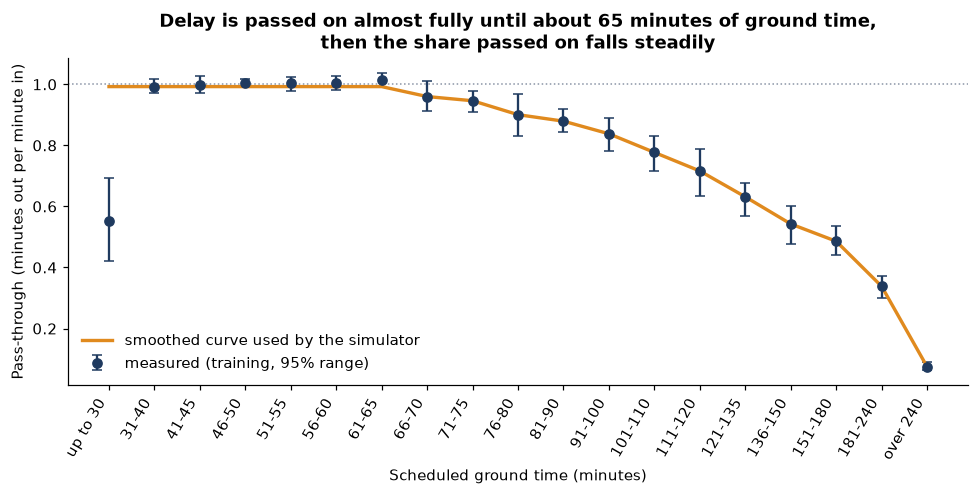

**What we see.** For turnarounds of 31 to about 63 minutes the pass-through is **0.99**: essentially all of the inbound delay is still there at departure.
(Only 2,751 turnarounds are planned at 30 minutes or less, and they are too few and too unusual to read much into, so the smoothed curve treats them like the next group.)
After about **63 minutes** the pass-through falls steadily and reaches **0.07** for turnarounds over 4 hours
(most of those are aircraft waiting for a later wave of flights, not turnarounds in the usual sense). So **extra minutes only start to pay off once a turnaround is already long enough.**

In [5]:
display(raw[["group", "n", "slope", "lo", "hi", "smooth"]].rename(columns={"group": "scheduled ground time (min)", "n": "turnarounds", "slope": "pass-through",
        "lo": "95% low", "hi": "95% high", "smooth": "smoothed"}).round(3).set_index("scheduled ground time (min)"))

fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(raw))
ax.errorbar(x, raw.slope, yerr=[raw.slope - raw.lo, raw.hi - raw.slope], fmt="o", color=BLUE, capsize=3, label="measured (training, 95% range)")
ax.plot(x, raw.smooth, color=ORANGE, lw=2.2, label="smoothed curve used by the simulator")
ax.axhline(1, color=GREY, ls=":", lw=1)
ax.set_xticks(x); ax.set_xticklabels(raw.group, rotation=60, ha="right")
ax.set_xlabel("Scheduled ground time (minutes)"); ax.set_ylabel("Pass-through (minutes out per minute in)")
ax.set_title("Delay is passed on almost fully until about 65 minutes of ground time,\nthen the share passed on falls steadily"); ax.legend()
save(fig, "fig04_passthrough_curve")

flat_to = raw.loc[(raw.smooth >= raw.smooth.max() - 0.03), "sg_mean"].max()
RESULTS["curve"] = [dict(group=r.group, n=int(r.n), slope=float(r.slope), lo=float(r.lo), hi=float(r.hi), smooth=float(r.smooth), sg_mean=float(r.sg_mean))
                    for r in raw.itertuples() if r.n and not np.isnan(r.slope)]
RESULTS["p_grid"] = {int(s): float(pass_through(s)) for s in range(0, 301, 5)}
RESULTS["flat_until"] = float(flat_to)
say(f"""**What we see.** For turnarounds of 31 to about {flat_to:.0f} minutes the pass-through is **{raw.smooth.iloc[1]:.2f}**: essentially all of the inbound delay is still there at departure.
(Only {int(raw.n.iloc[0]):,} turnarounds are planned at 30 minutes or less, and they are too few and too unusual to read much into, so the smoothed curve treats them like the next group.)
After about **{flat_to:.0f} minutes** the pass-through falls steadily and reaches **{raw.smooth.iloc[-1]:.2f}** for turnarounds over 4 hours
(most of those are aircraft waiting for a later wave of flights, not turnarounds in the usual sense). So **extra minutes only start to pay off once a turnaround is already long enough.**""")

## 3. Does the curve hold on data it has never seen?

A curve is only useful if it still works later. We take the curve fitted on **training** (Jan to Sep 2025) and ask it to predict the outbound delay for turnarounds in
**validation** (Oct to Dec 2025) and **test** (Jan to Aug 2026), given the inbound delay. We compare three simple predictors:

1. **Average:** always predict the training average outbound delay.
2. **One straight line:** a single pass-through number for all ground times (what a rule of thumb would use).
3. **Curve:** the pass-through curve above, with its own starting level for each ground-time group.

If the curve is real, it should beat the single line on later data. **Lower error is better; R² closer to 1 is better.**

In [6]:
# starting level (intercept) of each ground-time group, given the smoothed slope
raw["intercept"] = raw.D_mean - raw.smooth * raw.A_mean
ok_bins = raw.smooth.notna().values
def bin_of(sg):
    return np.clip(np.searchsorted(EDGES, np.asarray(sg), side="left") - 1, 0, len(EDGES) - 2)
def predict_curve(frame):
    b = bin_of(frame.sg.values)
    return raw.intercept.values[b] + pass_through(frame.sg.values) * frame.A.values

# one straight line for everything
n_, sA, sD = len(Ptr), Ptr.A.sum(), Ptr.D.sum()
slope_one = (n_ * (Ptr.A * Ptr.D).sum() - sA * sD) / (n_ * (Ptr.A ** 2).sum() - sA ** 2)
icpt_one = (sD - slope_one * sA) / n_
mean_D = Ptr.D.mean()

def scores(y, yhat):
    e = y - yhat
    return dict(MAE=float(np.abs(e).mean()), RMSE=float(np.sqrt((e ** 2).mean())), R2=float(1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()))

rows = []
for s in ["train", "validate", "test"]:
    F = T[(T.split == s) & (T.A > 0)]
    for name, yhat in [("1 Average", np.full(len(F), mean_D)), ("2 One straight line", icpt_one + slope_one * F.A.values), ("3 Curve", predict_curve(F))]:
        rows.append(dict(period=s, predictor=name, turnarounds=len(F), **scores(F.D.values, yhat)))
cmp_tab = pd.DataFrame(rows)
display(cmp_tab.round(3).set_index(["period", "predictor"]))
RESULTS["curve_vs_line"] = rows
RESULTS["single_slope"] = float(slope_one)

t_ = cmp_tab[cmp_tab.period == "test"].set_index("predictor")
v_ = cmp_tab[cmp_tab.period == "validate"].set_index("predictor")
say(f"""**Result.** On the unseen **test** period the curve gives an average error of **{t_.loc['3 Curve','MAE']:.1f} minutes**, against **{t_.loc['2 One straight line','MAE']:.1f}** for one straight line
and **{t_.loc['1 Average','MAE']:.1f}** for the plain average. R² is **{t_.loc['3 Curve','R2']:.2f}** with the curve and **{t_.loc['2 One straight line','R2']:.2f}** with one line
(validation: {v_.loc['3 Curve','R2']:.2f} and {v_.loc['2 One straight line','R2']:.2f}). {"The curve is better than one straight line on both later periods, so the shape is real and not an accident of the training months." if (t_.loc['3 Curve','MAE'] < t_.loc['2 One straight line','MAE'] and v_.loc['3 Curve','MAE'] < v_.loc['2 One straight line','MAE']) else "The curve is not clearly better than one straight line on both later periods, so we should not over-trust its shape."}""")

turnarounds     MAE    RMSE     R2
period   predictor                                              
train    1 Average                 175179  38.504  60.943  0.000
         2 One straight line       175179  27.151  50.381  0.317
         3 Curve                   175179  19.804  42.557  0.512
validate 1 Average                  56380  35.657  54.351 -0.003
         2 One straight line        56380  24.726  44.851  0.317
         3 Curve                    56380  17.620  36.821  0.540
test     1 Average                 148874  38.237  61.719 -0.003
         2 One straight line       148874  27.373  51.081  0.313
         3 Curve                   148874  19.172  42.134  0.533

**Result.** On the unseen **test** period the curve gives an average error of **19.2 minutes**, against **27.4** for one straight line
and **38.2** for the plain average. R² is **0.53** with the curve and **0.31** with one line
(validation: 0.54 and 0.32). The curve is better than one straight line on both later periods, so the shape is real and not an accident of the training months.

## 4. How many minutes does the next block of buffer buy?

This is the number the buffer engine actually needs. If we **add 10 minutes** of planned ground time to a turnaround that currently has a given ground time,
how much more of an inbound delay is absorbed? The answer is the drop in the curve over those 10 minutes.

**What to look for.** Which starting ground times give the largest gain? Where is extra buffer wasted?

,pass-through now,pass-through after +10 min,share of an inbound delay absorbed by the extra 10 min,minutes absorbed for a 30-minute inbound delay
starting ground time (min),,,,
25,0.993,0.993,0.000,0.000
40,0.993,0.993,0.000,0.000
50,0.993,0.993,0.000,0.000
60,0.993,0.954,0.039,1.156
70,0.954,0.894,0.060,1.790
80,0.894,0.859,0.035,1.050
90,0.859,0.809,0.051,1.524
100,0.809,0.749,0.060,1.790
120,0.684,0.617,0.068,2.029


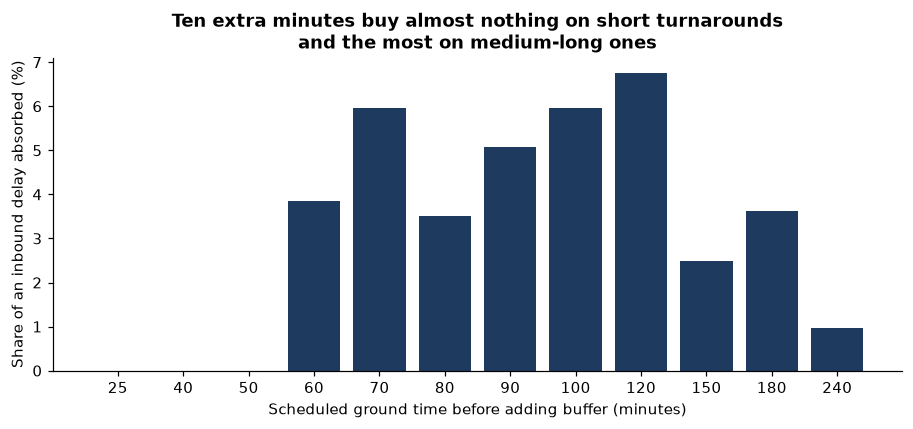

**What we see.** Adding 10 minutes gains the most when the turnaround already has about **120 minutes**: it absorbs about **7%** of an inbound delay
(about **2.0 minutes** for a 30-minute late arrival). On the shortest turnarounds (under about 60 minutes) the same 10 minutes absorbs close to nothing. This is the key
finding for the allocation engine: **spreading buffer evenly wastes much of it**, because short turnarounds cannot use a few extra minutes.

In [7]:
starts = [25, 40, 50, 60, 70, 80, 90, 100, 120, 150, 180, 240]
gain = pd.DataFrame({"starting ground time (min)": starts,
                     "pass-through now": pass_through(starts),
                     "pass-through after +10 min": pass_through([s + 10 for s in starts])})
gain["share of an inbound delay absorbed by the extra 10 min"] = gain.iloc[:, 1] - gain.iloc[:, 2]
gain["minutes absorbed for a 30-minute inbound delay"] = 30 * gain.iloc[:, 3]
display(gain.round(3).set_index("starting ground time (min)"))

fig, ax = plt.subplots(figsize=(8.4, 4))
ax.bar([str(s) for s in starts], 100 * gain.iloc[:, 3], color=BLUE)
ax.set_xlabel("Scheduled ground time before adding buffer (minutes)"); ax.set_ylabel("Share of an inbound delay absorbed (%)")
ax.set_title("Ten extra minutes buy almost nothing on short turnarounds\nand the most on medium-long ones")
save(fig, "fig05_gain_of_ten_minutes")
best = gain.loc[gain.iloc[:, 3].idxmax()]
RESULTS["gain_table"] = gain.round(4).to_dict(orient="records")
RESULTS["best_start"] = float(best["starting ground time (min)"]); RESULTS["best_gain"] = float(best.iloc[3])
say(f"""**What we see.** Adding 10 minutes gains the most when the turnaround already has about **{best['starting ground time (min)']:.0f} minutes**: it absorbs about **{100*best.iloc[3]:.0f}%** of an inbound delay
(about **{best.iloc[4]:.1f} minutes** for a 30-minute late arrival). On the shortest turnarounds (under about 60 minutes) the same 10 minutes absorbs close to nothing. This is the key
finding for the allocation engine: **spreading buffer evenly wastes much of it**, because short turnarounds cannot use a few extra minutes.""")

## 5. Does the curve look the same for different kinds of turnaround?

A curve learned on everything could hide big differences. We check four splits. For each, we measure pass-through in three ground-time bands
(**short** up to 55 minutes, **medium** 56 to 80, **long** over 80) so that groups with similar ground time are compared. These bands are chosen for readability, not tuned to any result.
We use all turnarounds here, since this is a description of the data and not a prediction.

**What to look for.** Do the bars (and their 95% ranges) differ between the two sides of each split? Where the bars are far apart, buffer should not be treated the same.

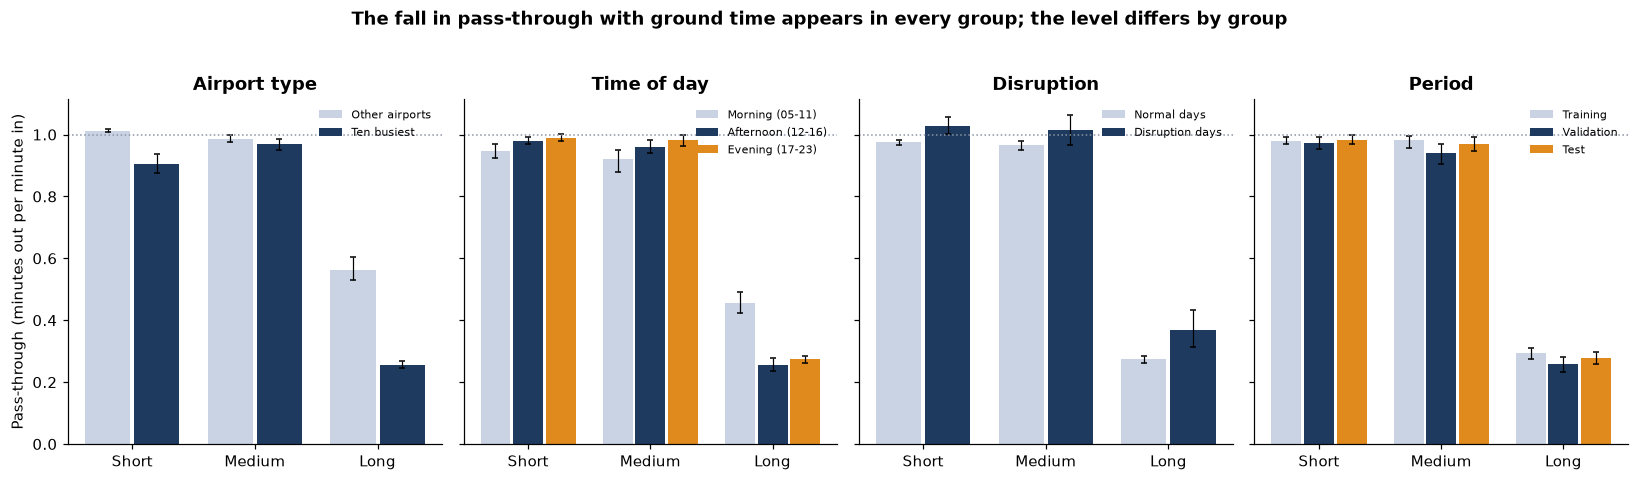

n  pass_through     lo     hi
split_type   segment           band                                                
Airport type Other airports    Short (up to 55)  103565         1.012  1.007  1.018
                               Medium (56-80)     27448         0.984  0.975  0.997
                               Long (over 80)     14013         0.562  0.529  0.604
             Ten busiest       Short (up to 55)   42034         0.904  0.875  0.938
                               Medium (56-80)    108086         0.969  0.949  0.987
                               Long (over 80)     85287         0.255  0.245  0.267
Time of day  Morning (05-11)   Short (up to 55)   26840         0.947  0.924  0.971
                               Medium (56-80)     24867         0.920  0.880  0.950
                               Long (over 80)     11942         0.456  0.424  0.491
             Afternoon (12-16) Short (up to 55)   62110         0.981  0.968  0.991
                               Medium (56-80)     43559         0.961  0.941  0.981
                               Long (over 80)     24755         0.257  0.237  0.278
             Evening (17-23)   Short (up to 55)   56649         0.990  0.980  1.003
                               Medium (56-80)     67108         0.982  0.963  0.998
                               Long (over 80)     62603         0.273  0.261  0.285
Disruption   Normal days       Short (up to 55)  140354         0.976  0.968  0.984
                               Medium (56-80)    130940         0.965  0.951  0.978
                               Long (over 80)     95149         0.273  0.263  0.284
             Disruption days   Short (up to 55)    5245         1.027  1.001  1.058
                               Medium (56-80)      4594         1.014  0.967  1.062
                               Long (over 80)      4151         0.369  0.312  0.432
Period       Training          Short (up to 55)   63082         0.981  0.970  0.993
                               Medium (56-80)     65185         0.981  0.958  0.995
                               Long (over 80)     46912         0.293  0.275  0.311
             Validation        Short (up to 55)   20971         0.973  0.953  0.993
                               Medium (56-80)     20741         0.940  0.906  0.969
                               Long (over 80)     14668         0.258  0.231  0.283
             Test              Short (up to 55)   61546         0.983  0.971  0.998
                               Medium (56-80)     49608         0.969  0.945  0.993
                               Long (over 80)     37720         0.277  0.260  0.297

In [8]:
Pall = T[T.A > 0].copy()
Pall["band"] = pd.cut(Pall.sg, [0, 55, 80, 100000], labels=False)
BANDS = ["Short (up to 55)", "Medium (56-80)", "Long (over 80)"]
Pall["tod"] = pd.cut(Pall.hr, [-1, 4, 11, 16, 23], labels=["night", "morning", "afternoon", "evening"])
SPLIT_DEFS = {
    "Airport type": ("hub", {0: "Other airports", 1: "Ten busiest"}),
    "Time of day": ("tod", {"morning": "Morning (05-11)", "afternoon": "Afternoon (12-16)", "evening": "Evening (17-23)"}),
    "Disruption": ("storm", {False: "Normal days", True: "Disruption days"}),
    "Period": ("split", {"train": "Training", "validate": "Validation", "test": "Test"}),
}
seg_rows = []
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
colors = [LIGHT, BLUE, ORANGE]
for ax, (title, (col, names)) in zip(axes, SPLIT_DEFS.items()):
    keys = list(names)
    sub = Pall[Pall[col].isin(keys)].copy()
    sub["grp"] = sub[col].map({k: i for i, k in enumerate(keys)}).astype(int) * 3 + sub.band.astype(int)
    labels = [f"{names[k]} | {b}" for k in keys for b in BANDS]
    tab = slope_table(sub, "grp", labels, B=150)
    for i, k in enumerate(keys):
        for j, b in enumerate(BANDS):
            r = tab.iloc[i * 3 + j]
            seg_rows.append(dict(split_type=title, segment=names[k], band=b, n=int(r.n), pass_through=float(r.slope), lo=float(r.lo), hi=float(r.hi)))
    w = 0.8 / len(keys)
    for i, k in enumerate(keys):
        r = tab.iloc[i * 3:(i + 1) * 3]
        xs = np.arange(3) + (i - (len(keys) - 1) / 2) * w
        ax.bar(xs, r.slope, width=w * 0.92, color=[LIGHT, BLUE, ORANGE, GREEN][i], label=names[k],
               yerr=[r.slope - r.lo, r.hi - r.slope], capsize=2, error_kw=dict(lw=0.8))
    ax.set_xticks(range(3)); ax.set_xticklabels(["Short", "Medium", "Long"]); ax.set_title(title); ax.legend(fontsize=7.5, loc="upper right")
    ax.axhline(1, color=GREY, ls=":", lw=1)
axes[0].set_ylabel("Pass-through (minutes out per minute in)")
fig.suptitle("The fall in pass-through with ground time appears in every group; the level differs by group", fontweight="bold", y=1.03)
save(fig, "fig06_segments")
SEG = pd.DataFrame(seg_rows); RESULTS["segments"] = seg_rows
display(SEG.round(3).set_index(["split_type", "segment", "band"]))

In [9]:
def seg(t, s, b): return float(SEG[(SEG.split_type == t) & (SEG.segment == s) & (SEG.band == b)].pass_through.iloc[0])
drop_all = [seg(t, s, "Short (up to 55)") - seg(t, s, "Long (over 80)") for t, d_ in SPLIT_DEFS.items() for s in d_[1].values()]
say(f"""**What we see.**
* **The shape is stable.** In all {len(drop_all)} groups, pass-through is lower for long ground times than for short ones (the smallest drop is {min(drop_all):.2f}, the largest {max(drop_all):.2f}). The curve is not caused by one airport type, one time of day or one season.
* **The level is not the same everywhere.** For long turnarounds, the ten busiest airports pass on {seg('Airport type','Ten busiest','Long (over 80)'):.2f} against {seg('Airport type','Other airports','Long (over 80)'):.2f} elsewhere;
  evenings pass on {seg('Time of day','Evening (17-23)','Long (over 80)'):.2f} against {seg('Time of day','Morning (05-11)','Long (over 80)'):.2f} in the morning; disruption days pass on {seg('Disruption','Disruption days','Long (over 80)'):.2f} against {seg('Disruption','Normal days','Long (over 80)'):.2f} on normal days.
* **Why this matters.** A buffer rule that uses one curve for everything would be too generous in some places and too tight in others. The simulator therefore reports results with and without disruption days, and by airport type.
* **Caution.** Long ground times at the busiest airports partly reflect how the airline plans its flight waves, so these gaps show association, not the effect of adding minutes.""")

**What we see.**
* **The shape is stable.** In all 10 groups, pass-through is lower for long ground times than for short ones (the smallest drop is 0.45, the largest 0.72). The curve is not caused by one airport type, one time of day or one season.
* **The level is not the same everywhere.** For long turnarounds, the ten busiest airports pass on 0.25 against 0.56 elsewhere;
  evenings pass on 0.27 against 0.46 in the morning; disruption days pass on 0.37 against 0.27 on normal days.
* **Why this matters.** A buffer rule that uses one curve for everything would be too generous in some places and too tight in others. The simulator therefore reports results with and without disruption days, and by airport type.
* **Caution.** Long ground times at the busiest airports partly reflect how the airline plans its flight waves, so these gaps show association, not the effect of adding minutes.

## 6. Saving the curve and a short summary

The curve is saved as a small table (`passthrough_curve.csv`) so that it can be inspected or reused. Notebook 06 rebuilds the same curve itself, so it also runs on its own.

In [10]:
curve_out = raw[["group", "n", "sg_mean", "slope", "lo", "hi", "smooth"]].rename(columns={"group": "ground_time_band_min", "sg_mean": "mean_ground_time_min",
            "slope": "pass_through_measured", "lo": "ci95_low", "hi": "ci95_high", "smooth": "pass_through_smoothed"}).round(4)
curve_out.to_csv(OUT / "passthrough_curve.csv", index=False)
say(f"""## Summary of notebook 04

1. **Delay is passed on almost one for one** on turnarounds of 31 to about {RESULTS['flat_until']:.0f} minutes, then the share passed on falls steadily (down to {raw.smooth.iloc[-1]:.2f} for the longest).
2. **The curve works on later data:** it beats a single straight line on both validation and test.
3. **Where buffer pays most:** +10 minutes absorbs the most delay when the turnaround already has about {RESULTS['best_start']:.0f} minutes ({100*RESULTS['best_gain']:.0f}% of an inbound delay). On very short turnarounds it absorbs almost nothing.
4. **The shape holds across airport types, times of day, disruption and period**, but the level differs, so risk should be taken into account (notebooks 05 and 06).
5. **Limits:** this shows association, not cause. A late inbound and a late outbound flight can share a cause such as weather, so every pass-through number is an upper bound on what buffer can truly absorb.""")
write_results("results_04_passthrough.json")

## Summary of notebook 04

1. **Delay is passed on almost one for one** on turnarounds of 31 to about 63 minutes, then the share passed on falls steadily (down to 0.07 for the longest).
2. **The curve works on later data:** it beats a single straight line on both validation and test.
3. **Where buffer pays most:** +10 minutes absorbs the most delay when the turnaround already has about 120 minutes (7% of an inbound delay). On very short turnarounds it absorbs almost nothing.
4. **The shape holds across airport types, times of day, disruption and period**, but the level differs, so risk should be taken into account (notebooks 05 and 06).
5. **Limits:** this shows association, not cause. A late inbound and a late outbound flight can share a cause such as weather, so every pass-through number is an upper bound on what buffer can truly absorb.

Saved results_04_passthrough.json and 3 chart files in the folder 'modelling_outputs'.
